In [142]:
# ============================================================
# EXPERIMENT NO. 8
# Linear Support Vector Machine (SVM)
# ============================================================

# Step 2: Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

In [143]:
# ============================================================
# Step 3: Load the Iris dataset
# ============================================================


df = pd.read_csv("D:/26-27/ODD/lab/Dataset/load_iris.csv")

print("Iris Dataset:")
print(df.head())

Iris Dataset:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   target  
0       0  
1       0  
2       0  
3       0  
4       0  


In [144]:
# ============================================================
# Step 4: Select first 100 samples
# corresponding to Setosa and Versicolor
# and choose first two features
# ============================================================

X = df.iloc[:100, :2].values

y = df.iloc[:100,4:5].values.ravel()

In [145]:
# ============================================================
# Step 5: Store selected features in X
# and class labels in y
# ============================================================

print("\nShape of X:", X.shape)
print("Shape of y:", y.shape)

print("\nFirst 5 feature values:")
print(X[:5])

print("\nFirst 5 class labels:")
print(y[:5])


Shape of X: (100, 2)
Shape of y: (100,)

First 5 feature values:
[[5.1 3.5]
 [4.9 3. ]
 [4.7 3.2]
 [4.6 3.1]
 [5.  3.6]]

First 5 class labels:
[0 0 0 0 0]


In [146]:
# ============================================================
# Step 6: Split dataset into training and testing sets
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTraining samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])


Training samples: 80
Testing samples: 20


In [147]:
# ============================================================
# Step 7: Create Linear SVM classifier
# ============================================================

svm_model = SVC(
    kernel="linear",
    C=200.0
)

In [148]:
# ============================================================
# Step 8: Train the SVM model
# ============================================================

svm_model.fit(
    X_train,
    y_train
)

,C,200.0
,kernel,'linear'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


In [149]:
# ============================================================
# Step 9: Predict class labels for test data
# ============================================================

y_pred = svm_model.predict(X_test)


print("\nPredicted Labels:")
print(y_pred)

print("\nActual Labels:")
print(y_test)


Predicted Labels:
[1 1 1 1 0 0 0 1 0 0 0 1 0 0 0 1 1 0 1 1]

Actual Labels:
[1 1 1 1 0 0 0 1 0 0 0 1 0 0 0 1 1 0 1 1]


In [150]:
# ============================================================

In [151]:
# Step 10: Evaluate model performance
# ============================================================

accuracy = accuracy_score(
    y_test,
    y_pred
)

print("\n==========================================")
print("MODEL PERFORMANCE")
print("==========================================")

print("Accuracy:", accuracy)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Setosa", "Versicolor"]
    )
)


MODEL PERFORMANCE
Accuracy: 1.0

Classification Report:
              precision    recall  f1-score   support

      Setosa       1.00      1.00      1.00        10
  Versicolor       1.00      1.00      1.00        10

    accuracy                           1.00        20
   macro avg       1.00      1.00      1.00        20
weighted avg       1.00      1.00      1.00        20




Support Vectors:
[[4.5 2.3]
 [5.5 3.5]
 [5.2 2.7]]

Number of Support Vectors:
3

Hyperplane equation:
w1*x1 + w2*x2 + b = 0

w1 = 5.453582687128703
w2 = -4.543856524423925
b  = -15.09057578380956


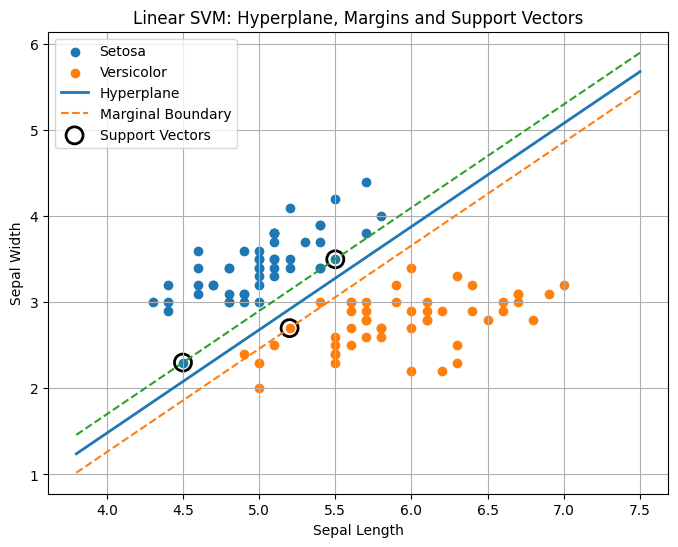

In [152]:
support_vectors = svm_model.support_vectors_

print("\nSupport Vectors:")
print(support_vectors)

print("\nNumber of Support Vectors:")
print(len(support_vectors))


# ============================================================
# Find Hyperplane parameters
# ============================================================

w = svm_model.coef_[0]
b = svm_model.intercept_[0]

print("\nHyperplane equation:")
print("w1*x1 + w2*x2 + b = 0")

print("\nw1 =", w[0])
print("w2 =", w[1])
print("b  =", b)


# ============================================================
# Create X values for plotting
# ============================================================

x = np.linspace(
    X[:, 0].min() - 0.5,
    X[:, 0].max() + 0.5,
    100
)


# ============================================================
# Hyperplane
# w1*x1 + w2*x2 + b = 0
# ============================================================

y_hyperplane = -(w[0] * x + b) / w[1]


# ============================================================
# Marginal boundaries
# w1*x1 + w2*x2 + b = +1
# w1*x1 + w2*x2 + b = -1
# ============================================================

y_margin_positive = -(w[0] * x + b - 1) / w[1]

y_margin_negative = -(w[0] * x + b + 1) / w[1]


# ============================================================
# Plot
# ============================================================

plt.figure(figsize=(8, 6))


# Plot Setosa
plt.scatter(
    X[y == 0, 0],
    X[y == 0, 1],
    label="Setosa"
)


# Plot Versicolor
plt.scatter(
    X[y == 1, 0],
    X[y == 1, 1],
    label="Versicolor"
)


# Hyperplane
plt.plot(
    x,
    y_hyperplane,
    linewidth=2,
    label="Hyperplane"
)


# Positive margin
plt.plot(
    x,
    y_margin_positive,
    linestyle="--",
    label="Marginal Boundary"
)


# Negative margin
plt.plot(
    x,
    y_margin_negative,
    linestyle="--"
)


# Support vectors
plt.scatter(
    support_vectors[:, 0],
    support_vectors[:, 1],
    s=150,
    facecolors="none",
    edgecolors="black",
    linewidths=2,
    label="Support Vectors"
)


plt.xlabel("Sepal Length")
plt.ylabel("Sepal Width")

plt.title("Linear SVM: Hyperplane, Margins and Support Vectors")

plt.legend()
plt.grid(True)

plt.show()